# Animacja mesha i chmury punktów

Zbudujesz animację, w której punkty podążają za odkształcaną powierzchnią. Najpierw obejrzysz ruch chorągiewki i jej próbek. Potem sprawdzisz na jednym dużym trójkącie, kiedy deformacja punktu i odtworzenie jego położenia z wierzchołków dają różne wyniki.

Uruchomcie komórki od góry i obejrzyjcie animację chorągiewki. Wystarczy CPU. Po zajęciach możecie też wczytać mesh z notebooka 02 i go animować.

**Zadanie dodatkowe do domu** to [Punkt na deformowanym trójkącie](#punkt-na-deformowanym-trojkacie).

In [1]:
from io import BytesIO
from pathlib import Path

import ipywidgets as widgets
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Image, display
from matplotlib.backends.backend_agg import FigureCanvasAgg
from matplotlib.figure import Figure
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
from PIL import Image as PILImage

BG, INK = "#F8FAFC", "#0F172A"
BLUE, ORANGE, TEAL = "#2563EB", "#EA580C", "#0F766E"
SECONDARY, GRAY, GRID = "#64748B", "#94A3B8", "#CBD5E1"
plt.rcParams.update(
    {
        "font.family": "DejaVu Sans",
        "mathtext.fontset": "dejavusans",
        "figure.facecolor": BG,
        "axes.facecolor": BG,
        "text.color": INK,
        "axes.labelcolor": INK,
        "axes.edgecolor": GRAY,
        "axes.titlecolor": INK,
        "xtick.color": SECONDARY,
        "ytick.color": SECONDARY,
        "grid.color": GRID,
        "figure.dpi": 115,
    }
)


def show(fig):
    display(fig)
    plt.close(fig)


def controls(function, **parameters):
    output = widgets.interactive_output(function, parameters)
    row = widgets.HBox(list(parameters.values()), layout=widgets.Layout(flex_flow="row wrap"))
    display(widgets.VBox([row, output]))

## 1. Mesh i próbki powierzchni

Mesh składa się ze współrzędnych wierzchołków `vertices` i trójek ich indeksów `faces`. Podczas deformacji zmieniamy współrzędne. Indeksy pozostają te same, więc w każdej klatce da się odnaleźć ten sam trójkąt. Będziemy z niego odtwarzać położenie przyczepionego punktu. [Pharr, Jakob i Humphreys, 2023, §6.5](https://pbr-book.org/4ed/Shapes/Triangle_Meshes).

Własny przykład używa prostokątnej chorągiewki podzielonej na trójkąty. Opcjonalnie ustaw `MESH_FILE = "mesh_gs.npz"`, aby wczytać mesh wyeksportowany z notebooka 02.

In [2]:
def flag_mesh(columns=17, rows=9):
    x = np.linspace(-1.0, 1.0, columns)
    y = np.linspace(-0.52, 0.52, rows)
    xx, yy = np.meshgrid(x, y)
    vertices = np.column_stack((xx.ravel(), yy.ravel(), np.zeros(xx.size)))
    grid = np.arange(xx.size).reshape(rows, columns)
    a = grid[:-1, :-1].ravel()
    b = grid[:-1, 1:].ravel()
    c = grid[1:, :-1].ravel()
    d = grid[1:, 1:].ravel()
    faces = np.vstack((np.column_stack((a, b, c)), np.column_stack((b, d, c))))
    return vertices, faces


MESH_FILE = None  # Opcjonalnie: "mesh_gs.npz" z notebooka 02.
if MESH_FILE is None:
    vertices, faces = flag_mesh()
else:
    with np.load(Path(MESH_FILE), allow_pickle=False) as mesh_data:
        vertices, faces = mesh_data["vertices"], mesh_data["faces"]

x_min, x_max = vertices[:, 0].min(), vertices[:, 0].max()

### Współrzędne barycentryczne

Wagi opisują położenie względem trzech wierzchołków. Wagi $(1,0,0)$ wybierają pierwszy wierzchołek, a $(1/3,1/3,1/3)$ środek ciężkości trójkąta. Dla punktu na trójkącie wystarczy zapamiętać jego trzy indeksy i nieujemne wagi o sumie jeden. Po deformacji podstawiamy aktualne wierzchołki:

$$\mathbf{p}(t)=\lambda_1\mathbf{v}_1(t)+\lambda_2\mathbf{v}_2(t)+\lambda_3\mathbf{v}_3(t).$$

W demonstracji trójkąty losujemy proporcjonalnie do ich pól, a położenia równomiernie wewnątrz wybranych trójkątów. W ten sposób większy trójkąt otrzymuje średnio więcej punktów. [Pharr, Jakob i Humphreys, 2023, §6.5.4 Sampling](https://pbr-book.org/4ed/Shapes/Triangle_Meshes#sec:triangle-sampling).

In [3]:
def sample_surface(vertices, faces, count, seed=19):
    triangles = vertices[faces]
    a, b, c = triangles.transpose(1, 0, 2)
    area = 0.5 * np.linalg.norm(np.cross(b - a, c - a), axis=1)
    rng = np.random.default_rng(seed)
    triangle_ids = rng.choice(len(faces), size=count, p=area / area.sum())
    u, v = rng.random((2, count))
    s = np.sqrt(u)
    weights = np.column_stack((1 - s, s * (1 - v), s * v))
    return faces[triangle_ids], weights


def interpolate_points(vertices, point_triangle_vertices, barycentric_weights):
    triangles = vertices[point_triangle_vertices]
    return np.einsum("ni,nij->nj", barycentric_weights, triangles)


point_triangles, weights = sample_surface(vertices, faces, count=1100)
rest_points = interpolate_points(vertices, point_triangles, weights)

## 2. Deformacja chorągiewki

Współrzędną $x$ sprowadzamy do przedziału $u\in[0,1]$. Zmieniamy wysokość o

$$\Delta z=A\,u\sin(2\pi u-\varphi).$$

Amplituda $A$ określa siłę deformacji, a faza $\varphi$ zmienia się z klatką. Czynnik $u$ wygasza falę w miejscu mocowania: dla $u=0$ przesunięcie wynosi zero w każdej klatce. Własna demonstracja, wykresy i animacja.

Porównaj amplitudy 0 i 0,65 oraz klatki 0, 6 i 12. Pomarańczowy znacznik pokazuje ten sam punkt w obu reprezentacjach.

In [4]:
def deform(points, phase, amplitude, bounds=None):
    left, right = (x_min, x_max) if bounds is None else bounds
    u = (points[:, 0] - left) / (right - left)
    dz = amplitude * u * np.sin(2 * np.pi * u - phase)
    moved = points.copy()
    moved[:, 2] += dz
    return moved


def frame_geometry(phase, amplitude):
    moved_vertices = deform(vertices, phase, amplitude)
    moved_points = interpolate_points(moved_vertices, point_triangles, weights)
    return moved_vertices, moved_points


# Śledzimy ten sam punkt także po przesunięciu suwaka.
tracked = np.argmin((rest_points[:, 0] - 0.58) ** 2 + rest_points[:, 1] ** 2)
fixed_vertices = np.isclose(vertices[:, 0], x_min)

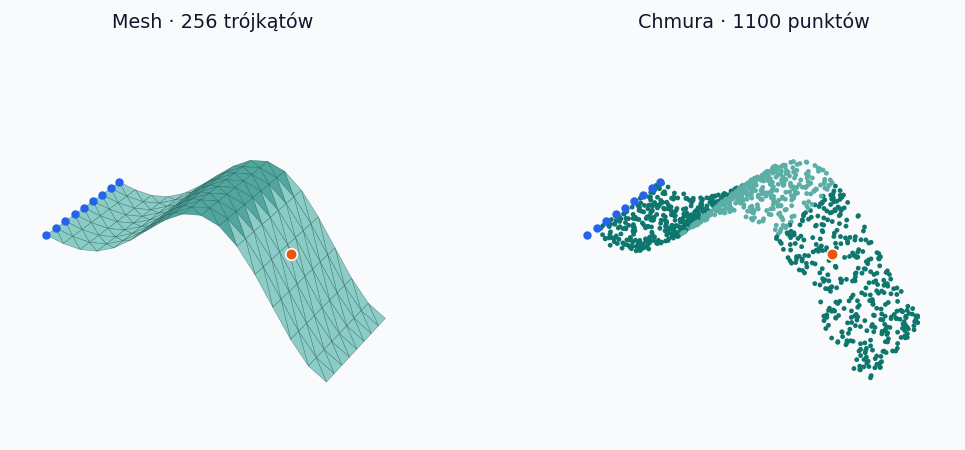

In [5]:
def frame_figure(phase, amplitude=0.65, azimuth=-63, figure=None):
    fig = plt.figure(figsize=(9.4, 3.8), layout="constrained") if figure is None else figure
    fig.clear()
    moved, points = frame_geometry(phase, amplitude)
    triangles = moved[faces]
    rest_x = vertices[faces, 0].mean(axis=1)
    stripes = ((rest_x - x_min) / (x_max - x_min) * 3).astype(int) % 2
    facecolors = np.array(["#8BCCC6", "#51A69D"])[stripes]
    ax_mesh, ax_cloud = [
        fig.add_subplot(1, 2, i, projection="3d", computed_zorder=False) for i in (1, 2)
    ]
    ax_mesh.add_collection3d(
        Poly3DCollection(
            triangles, facecolors=facecolors, edgecolors=(0.04, 0.27, 0.26, 0.53), linewidths=0.32
        )
    )
    point_stripes = ((rest_points[:, 0] - x_min) / (x_max - x_min) * 3).astype(int) % 2
    ax_cloud.scatter(
        *points.T, c=np.array([TEAL, "#5BAEA5"])[point_stripes], s=4, depthshade=False
    )
    ax_mesh.set_title(f"Mesh · {len(faces)} trójkątów")
    ax_cloud.set_title(f"Chmura · {len(points)} punktów")
    # Punkt i podpory widoczne na obu reprezentacjach. Limity są wspólne dla wszystkich klatek.
    supports = moved[fixed_vertices]
    z_bound = max(1.0, np.abs(vertices[:, 2]).max() + amplitude)
    for ax in (ax_mesh, ax_cloud):
        ax.scatter(*supports.T, s=18, color=BLUE, depthshade=False, zorder=5)
        ax.scatter(
            *points[tracked],
            s=52,
            color=ORANGE,
            edgecolor="white",
            linewidth=1.0,
            depthshade=False,
            zorder=8,
        )
        x_lim = max(1.12, float(np.abs(vertices[:, 0]).max()) + 0.08)
        y_lim = max(1.04, float(np.abs(vertices[:, 1]).max()) + 0.08)
        ax.set(xlim=(-x_lim, x_lim), ylim=(-y_lim, y_lim), zlim=(-z_bound, z_bound))
        ax.set_box_aspect((2 * x_lim, 2 * y_lim, 2 * z_bound), zoom=1.34)
        ax.view_init(elev=23, azim=azimuth)
        ax.set_axis_off()
    return fig


def show_frame(frame=6, amplitude=0.65, azimuth=-63):
    show(frame_figure(2 * np.pi * frame / 24, amplitude, azimuth))


controls(
    show_frame,
    frame=widgets.IntSlider(description="Klatka", min=0, max=23, value=6, continuous_update=False),
    amplitude=widgets.FloatSlider(
        description="Amplituda", min=0, max=0.9, step=0.05, value=0.65, continuous_update=False
    ),
    azimuth=widgets.IntSlider(
        description="Obrót", min=-180, max=180, step=5, value=-65, continuous_update=False
    ),
)

### Pełny cykl animacji

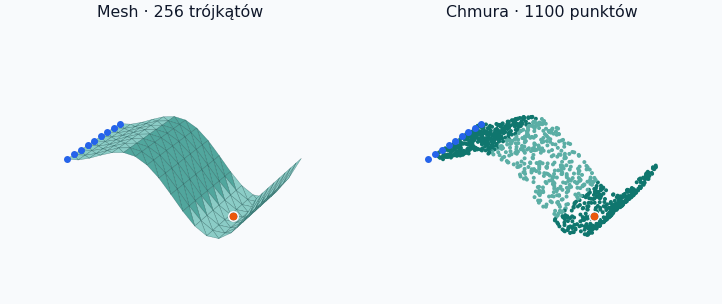

In [6]:
def animation_gif(amplitude=0.65, frames=24):
    fig = Figure(figsize=(7.6, 3.2), dpi=95, layout="constrained", facecolor=BG)
    canvas = FigureCanvasAgg(fig)
    images = []
    for phase in np.linspace(0, 2 * np.pi, frames, endpoint=False):
        frame_figure(phase, amplitude, figure=fig)
        canvas.draw()
        images.append(PILImage.fromarray(np.asarray(canvas.buffer_rgba()).copy()).convert("RGB"))
    buffer = BytesIO()
    images[0].save(
        buffer,
        format="GIF",
        save_all=True,
        append_images=images[1:],
        duration=85,
        loop=0,
        disposal=2,
    )
    return buffer.getvalue()


gif_bytes = animation_gif()
display(Image(data=gif_bytes, format="gif"))

## 3. Interpolacja a bezpośrednia deformacja

Gdy deformujemy wierzchołki, renderer nadal rysuje płaski trójkąt między nimi. Gdy zastosujemy sinusoidę bezpośrednio do punktu wewnątrz, jego wysokość wynika z wartości fali w tym konkretnym miejscu. Rysunek autorów pokazuje obie trajektorie w tej samej klatce.

$$\mathbf{p}_\mathrm{mesh}=\sum_i\lambda_i F(\mathbf{v}_i),\qquad \mathbf{p}_\mathrm{direct}=F\!\left(\sum_i\lambda_i\mathbf{v}_i\right).$$

Dla transformacji afinicznej $F(\mathbf{v})=A\mathbf{v}+\mathbf{b}$ wyniki są równe, ponieważ suma wag wynosi jeden i składnik przesunięcia daje $\sum_i\lambda_i\mathbf{b}=\mathbf{b}$. Dla sinusoidy rozbieżność zależy od miejsca na fali i od rozmiaru trójkąta. Pomarańczowy punkt jest obliczany z wierzchołków, a niebieski krzyżyk z bezpośredniego odkształcenia.

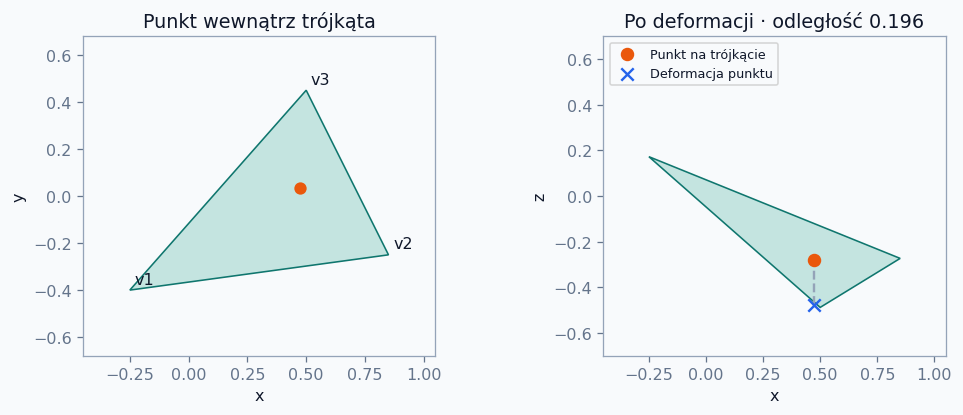

In [7]:
# Duży trójkąt uwidacznia różnicę między deformacją a interpolacją.
triangle_demo = np.array([[-0.25, -0.4, 0.0], [0.85, -0.25, 0.0], [0.50, 0.45, 0.0]])
bary_demo = np.array([0.20, 0.35, 0.45])


def triangle_figure(phase, amplitude, attached=None):
    # Używamy tej samej skali x co na chorągiewce, niezależnie od opcjonalnego importu.
    raised = deform(triangle_demo, phase, amplitude, bounds=(-1.0, 1.0))
    initial = bary_demo @ triangle_demo
    direct = deform(initial[None, :], phase, amplitude, bounds=(-1.0, 1.0))[0]
    attached_point = (bary_demo @ raised) if attached is None else attached(raised, bary_demo)

    fig, axes = plt.subplots(1, 2, figsize=(9, 3.5), layout="constrained")
    left, right = axes
    left.fill(*triangle_demo[:, :2].T, facecolor="#C4E4E0", edgecolor=TEAL)
    left.scatter(*initial[:2], color=ORANGE, s=45)
    for i, (x, y, _) in enumerate(triangle_demo):
        left.annotate(f"v{i+1}", (x, y), xytext=(3, 4), textcoords="offset points")
    left.set(
        title="Punkt wewnątrz trójkąta",
        xlabel="x",
        ylabel="y",
        aspect="equal",
        xlim=(-0.45, 1.05),
        ylim=(-0.68, 0.68),
    )
    right.fill(raised[:, 0], raised[:, 2], facecolor="#C4E4E0", edgecolor=TEAL)
    right.plot([direct[0], attached_point[0]], [direct[2], attached_point[2]], "--", color=GRAY)
    right.scatter(
        *attached_point[[0, 2]], color=ORANGE, s=55, label="Punkt na trójkącie", zorder=3
    )
    right.scatter(
        *direct[[0, 2]], color=BLUE, marker="x", s=60, label="Deformacja punktu", zorder=4
    )
    delta = np.linalg.norm(direct - attached_point)
    right.set(
        title=f"Po deformacji · odległość {delta:.3f}",
        xlabel="x",
        ylabel="z",
        aspect="equal",
        xlim=(-0.45, 1.05),
        ylim=(-0.7, 0.7),
    )
    right.legend(fontsize=8, loc="upper left")
    return fig


show(triangle_figure(0, 0.65))

<a id="punkt-na-deformowanym-trojkacie" name="punkt-na-deformowanym-trojkacie"></a>

### Zadanie dodatkowe do domu - Punkt na deformowanym trójkącie

Wyobraźcie sobie, że na chorągiewce jest namalowana kropka. Gdy materiał faluje, kropka powinna dalej leżeć na jego powierzchni. Sprawdźcie, czy wystarczy ją odkształcić tą samą falą co wierzchołki. Skrót zadania znajdziecie na slajdzie „Punkt na deformowanym trójkącie”.

1. Jak myślicie, która metoda zachowa położenie kropki względem trzech wierzchołków trójkąta?
2. W `attached_point` obliczcie sumę ważoną trzech wierzchołków z `moved_triangle`. Wybierzcie amplitudę z zakresu `0.3`–`0.9` i uruchomcie komórkę. Jeśli utkniecie, sprawdźcie najpierw, jaki punkt powinny dać wagi `[1, 0, 0]`.
3. Komórka pokaże oba sposoby przesuwania kropki dla wybranej amplitudy i dla `0`. Porównajcie odległości podane nad prawymi wykresami. Którego sposobu użylibyście, żeby kropka podążała za chorągiewką?

In [ ]:
def attached_point(moved_triangle, barycentric):
    return None  # TODO 1. Połącz trzy aktualne wierzchołki za pomocą trzech wag.


test_amplitude = None  # TODO 2. Wybierz amplitudę od 0.3 do 0.9.

if attached_point(triangle_demo, bary_demo) is None or test_amplitude is None:
    print("Uzupełnij oba TODO, a następnie porównaj oba położenia punktu.")
elif not (0.3 <= test_amplitude <= 0.9):
    print("Wybierz amplitudę z przedziału [0.3, 0.9].")
else:
    # Próby na wierzchołkach i wewnątrz trójkąta, także po przesunięciu w przestrzeni.
    probes = np.vstack((np.eye(3), bary_demo))
    moved_triangle = triangle_demo + [0.4, 0.1, -0.3]
    valid = all(
        np.shape(attached_point(moved_triangle, b)) == (3,)
        and np.allclose(attached_point(moved_triangle, b), b @ moved_triangle)
        for b in probes
    )
    if valid:
        show(triangle_figure(0, test_amplitude, attached=attached_point))
        show(triangle_figure(0, 0, attached=attached_point))
    else:
        print("Podstaw wagi [1, 0, 0]. Wynik powinien być pierwszym wierzchołkiem.")

### Podsumowanie

| Reprezentacja | Stałe dane | Aktualizacja w klatce |
| --- | --- | --- |
| Mesh | Indeksy trójkątów | Położenia wierzchołków |
| Punkty na powierzchni | Przypisany trójkąt i wagi | Suma ważona aktualnych wierzchołków |

Po zmianie topologii siatki trzeba odnowić przypisania punktów. Zastosowana fala opisuje ruch, bez symulacji fizyki tkaniny.

## Źródła

- Pharr, Jakob i Humphreys (2023), [współrzędne barycentryczne](https://pbr-book.org/4ed/Shapes/Triangle_Meshes) i [jednostajne próbkowanie trójkąta](https://pbr-book.org/4ed/Shapes/Triangle_Meshes#sec:triangle-sampling).